In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import pickle
import analyses as als
import datasets as ds
# import models as mds
# import tools

2024-04-15 12:39:44.004179: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-04-15 12:39:44.062417: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-04-15 12:39:44.062483: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-04-15 12:39:44.063893: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-04-15 12:39:44.072101: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-04-15 12:39:44.072855: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [3]:
def collective_modes(modes, saturate=1.5, squared_entries=False, plot_params={}):
    ''' Plot a collection of modes with the same color range and a colorbar '''
    num_h = len(modes)
    fig = plt.figure(constrained_layout=True, figsize=[num_h, 7], **plot_params)
    gs = mpl.gridspec.GridSpec(1, num_h, figure=fig)
    ax = np.array([None] * num_h)

    # Calculate the maximum absolute value across all modes for consistent scaling
    vmax = max([max(np.amax(mode), -np.amin(mode)) for mode in modes])
    
    for n in range(num_h):
        ax[n] = fig.add_subplot(gs[0, n])
        cur_mode = modes[n]

        if squared_entries: 
            filter_plot = ax[n].imshow(cur_mode**2, interpolation='none', cmap='Blues')
        else:
            adjusted_vmax = vmax**(1/saturate)
            filter_plot = ax[n].imshow(np.abs(cur_mode)**(1/saturate) * np.sign(cur_mode), cmap='bwr', vmax=adjusted_vmax, vmin=-adjusted_vmax)
        
        ax[n].set_yticks([])
        ax[n].set_xticks([])
        ax[n].set_xlabel(f"MN {1 + n}")

    # Add a colorbar to the figure
    fig.colorbar(filter_plot, ax=ax.ravel().tolist(), shrink=0.95)

    return fig, ax


In [5]:
K = 10
N = 93
V_width = 7
V_E_buffer = 0
E_width = 1
setup = (V_width, V_E_buffer, E_width)
stim = "opticflow"
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', stim)

## Meta neuron modes

In [6]:
def filename(v, b, e, K):
    return f'({v},{b},{e}) K={K}.dat'

load_path = os.path.join(bank_directory, filename(*setup, K))
with open(load_path, 'rb') as f:
    bank_data = pickle.load(f)
basis_vectors = bank_data["basis_vectors"]

In [7]:
modes = []
for i in range(K):
    modes.append(basis_vectors[:,i].reshape((V_width, N)).T)

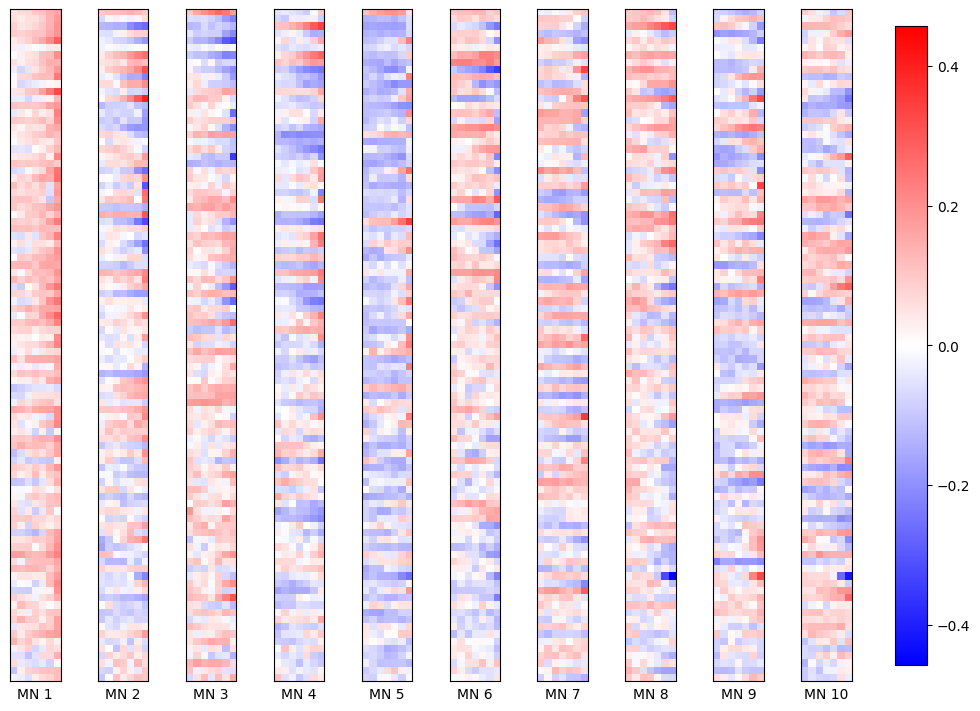

In [8]:
fig, ax = collective_modes(modes)

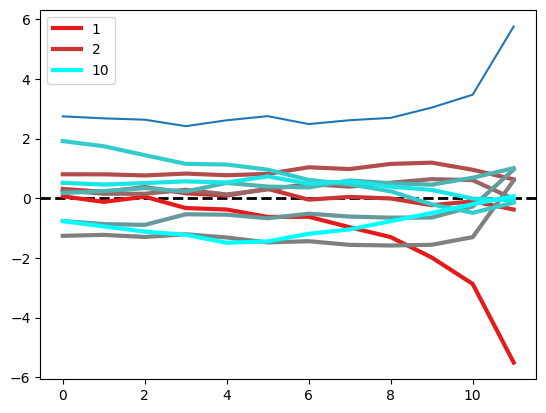

In [22]:
plt.axhline(0, color='k', linestyle='--', linewidth=2)

label_inds = [0,1,K-1]
activity_component = np.zeros((K, V_width))
for i in range(K):
    l = (i+1) / K
    # y = np.sqrt(np.sum(modes[i]**2, axis=0))
    # y = y / np.max(y)

    y = np.sum(modes[i], axis=0)
    # y = y * np.sign(y[0])
    # y = y * np.sign(np.sum(y))

    activity_component[i] = y
    label = f"{i+1}" if i in label_inds else None
    plt.plot(y, label=label, color=(1-l,l,l), linewidth=3);
    # plt.plot(y, label=f"{i+1}", color=(1-l,l,l), linewidth=3);

plt.plot(np.sqrt(np.sum(activity_component**2, axis=0)))
plt.legend()

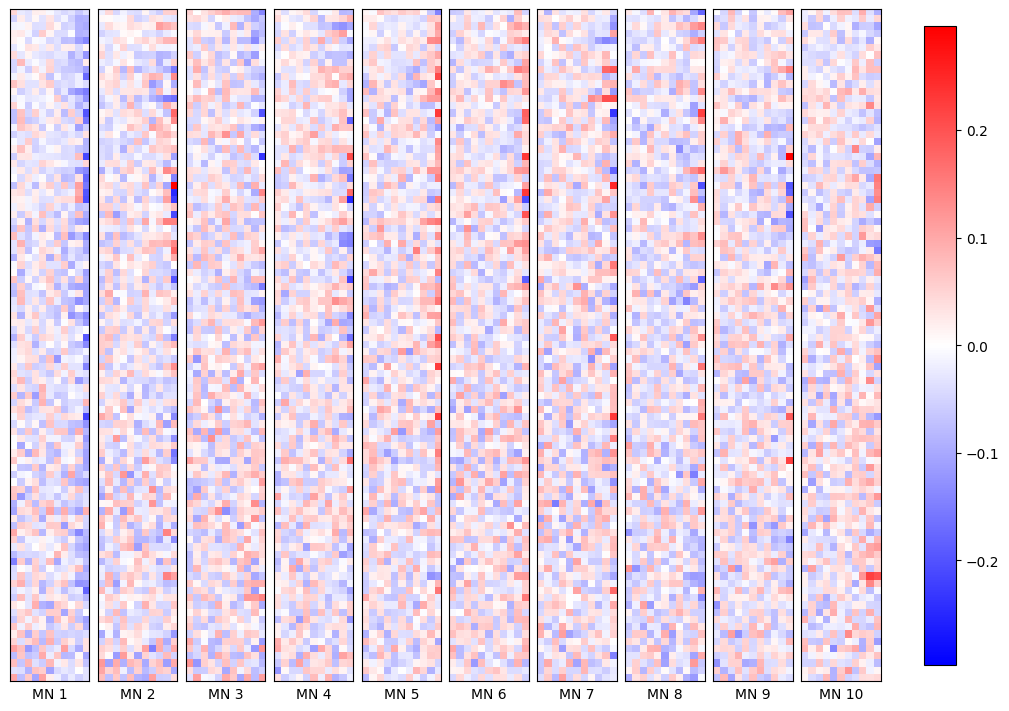

In [23]:
modes_diff = [np.diff(a, axis=1) for a in modes]
fig, ax = collective_modes(modes_diff)

In [24]:
mode_diff_norms = [np.sqrt(np.sum(a**2)) for a in modes_diff]
mode_diff_norms

[0.5731626414034441,
 0.5865906103406774,
 0.5277413492052742,
 0.5151932112906314,
 0.5621430548708977,
 0.5410257810346634,
 0.5821282580051002,
 0.5320649301733349,
 0.5126076698437197,
 0.5129852887306116]

## PCA modes

In [29]:
neural_data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
D = ds.DataNatScenes(neural_data_path, mov_ind=4)
print(f'current stimulus is {D.movname}')

current stimulus is opticflow


In [30]:
D.reset()
D.trim(20)
V, E = D.create_V_and_E_datasets(*setup, samp_keep=1)

In [31]:
lam, basis_pca = als.pca(V.X)
pca_modes = []
for i in range(K):
    pca_modes.append(basis_pca[:,i].reshape((V_width, N)).T)

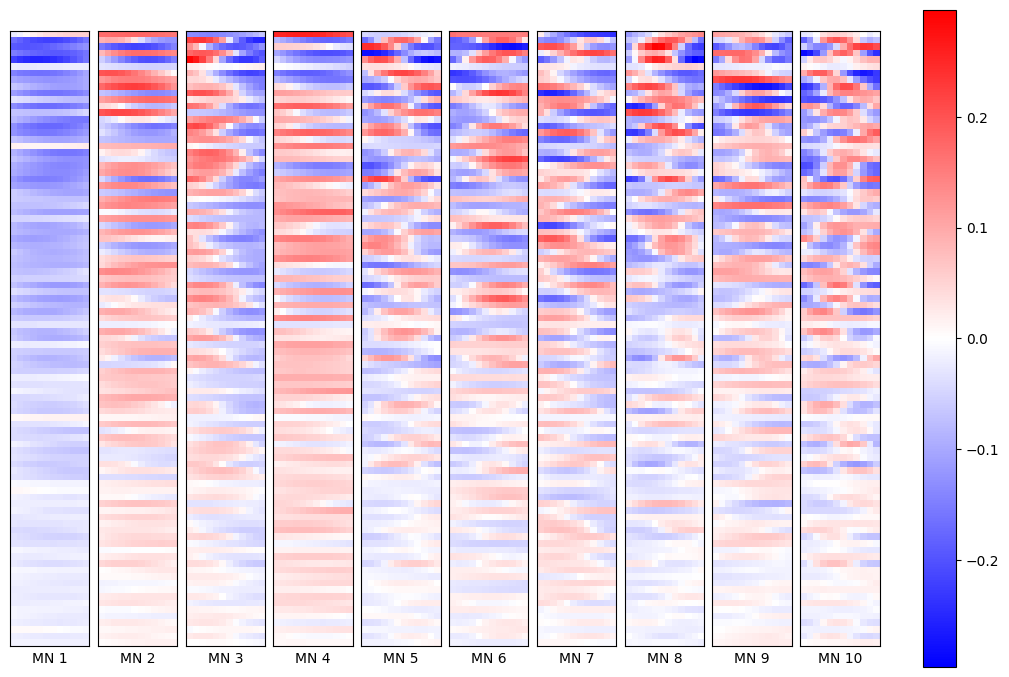

In [32]:
fig, ax = collective_modes(pca_modes)

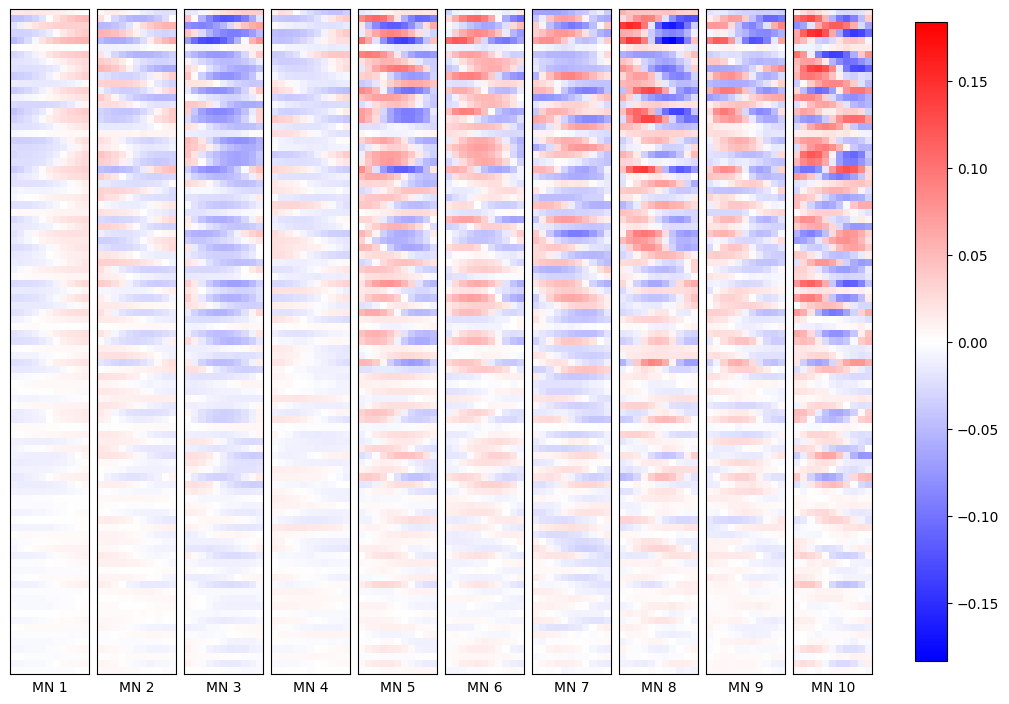

In [33]:
pca_modes_diff = [np.diff(a, axis=1) for a in pca_modes]
fig, ax = collective_modes(pca_modes_diff)